In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
listings_raw = pd.read_csv('../data/listings_clean_outlier.csv', parse_dates=['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review'])
listings = listings_raw.copy()
listings.days_since_review = pd.to_numeric(
    listings.days_since_review.str.replace(' ', '').str.replace('days', ''), errors='coerce')
listings.shape

(4574, 74)

## 1) "A night in Stockholm costs 1,791"

In [13]:
listings.price.describe()

count     2957.000000
mean      2327.643382
std       2160.353619
min        120.000000
25%       1071.120000
50%       1791.000000
75%       3003.800000
max      40000.000000
Name: price, dtype: float64

In [16]:
one_night_and_available = listings[(listings.availability_365 > 0) & (listings.minimum_nights == 1)]
one_night_and_available.price.describe()

count     1017.000000
mean      2025.494897
std       2352.901418
min        120.000000
25%        896.900000
50%       1378.000000
75%       2388.000000
max      30000.000000
Name: price, dtype: float64

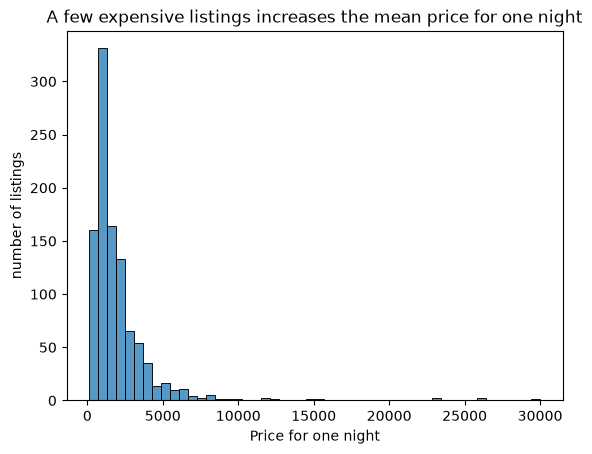

In [19]:
fig, ax = plt.subplots()
sns.histplot(data=one_night_and_available, x='price', bins=50, ax=ax)
ax.set_title('A few expensive listings increases the mean price for one night')
ax.set_ylabel('number of listings')
ax.set_xlabel('Price for one night')
plt.show()

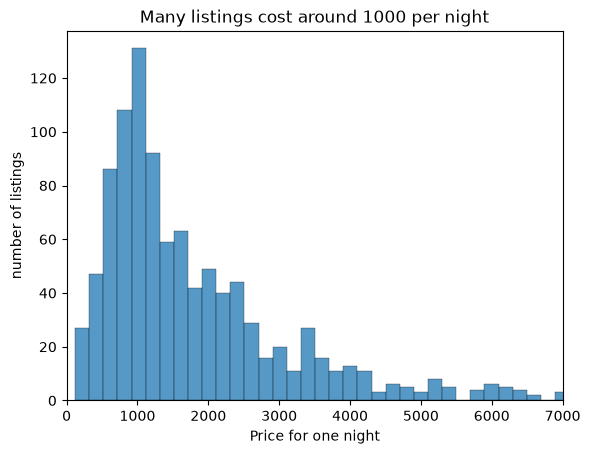

In [26]:
fig, ax = plt.subplots()
sns.histplot(data=one_night_and_available, x='price', bins=150, ax=ax)
ax.set_title('Many listings cost around 1000 per night')
ax.set_xlim(0,7000)
ax.set_ylabel('number of listings')
ax.set_xlabel('Price for one night')
plt.show()

In [56]:
price_near_1791 = listings[(listings.availability_365 > 0) & (listings.minimum_nights == 1) & (listings.price >= 1600) & (listings.price <=2000)]
print(price_near_1791.id.count())
print(round(104/1017*100,1))

104
10.2


About 104 out of 1017 listings that are available for one night cost between 1600 and 2000 for one night. That is just 10.2%

The original value comes from the mean of all listings (even those not available for 1 night only as well as those that cannot be booked for the next 365 days (either fully booked or unlisted))

Just looking at available one night listings the mean price for one night is 1378 and the average price for one night is 2025

Verdict: does not hold. The number 1791 is valid number but describes something other than what was stated 'A night in Stockholm costs 1791'.

New sentance: Out of 1017 listings in Stockholm available for one night, the mean price for one night is 1378 and 50% of those listings cost between 897 and 2388 for one night.

## 2) "The listings with a perfect 5.00 rating are the best in Stockholm."

In [60]:
rated = listings[listings.has_reviews]
perfect = rated.review_scores_rating == 5
review_group = pd.cut(
    rated.number_of_reviews,
    bins=[0,1,5,20,10000],
    labels=['1 review', '2-5 reviews', '6-20 reviews', '21+ reviews']
)
perfect.groupby(review_group).agg(
    ['count', 'mean']
).round(2)

,count,mean
number_of_reviews,,
1 review,319,0.84
2-5 reviews,852,0.71
6-20 reviews,1271,0.38
21+ reviews,1488,0.08


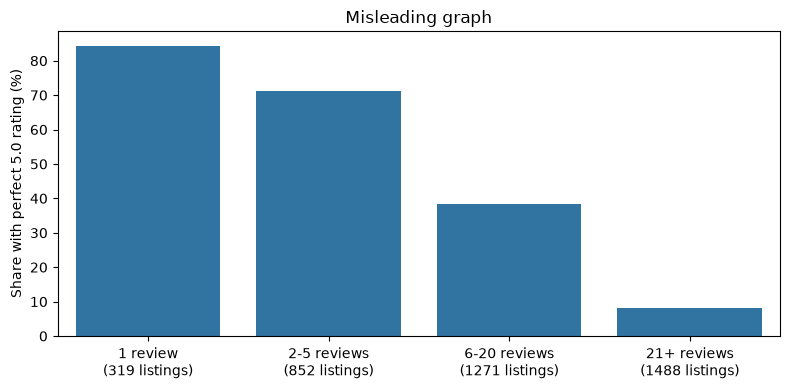

In [61]:
result = perfect.groupby(review_group).agg(['count', 'mean']).reset_index()
result['percent'] = result['mean'] * 100
result['label'] = result['number_of_reviews'].astype(str) + '\n('+ result['count'].astype(str) +' listings)'
fig, ax = plt.subplots(figsize=(8,4))
sns.barplot(data=result, x='label', y='percent', ax=ax)
ax.set_title('Misleading graph')
ax.set_xlabel('')
ax.set_ylabel('Share with perfect 5.0 rating (%)')
plt.tight_layout()
plt.show()

In [68]:
print(round(100* pow(0.84,21),1))

2.6


84 percent of listings with 1 review have a perfect score 5.0

8 percent of listings with 21 or more reviews have a perfect score of 5.0

Assuming that 84 percent of the reviews in the 21+ reviews category were 5.0,
the expected percentage of perfect 5.0 listings in the 21+ reviews category would be at most 2.6 percent and that's even an overestimate as it assumes they all have exactly 21 reviews.

If we were to draw any conclusions from the above graph it should be that listings with only 1 review have very low share of perfect score compared to listings with perfect score with more reviews.

In [69]:
listings.review_scores_rating.describe()

count    3930.000000
mean        4.817692
std         0.317372
min         1.000000
25%         4.750000
50%         4.920000
75%         5.000000
max         5.000000
Name: review_scores_rating, dtype: float64

Verdict: Does not hold. Having a perfect 5.0 rating is more of an indicator that a listing has few reviews than it is an indicator of quality.

New Sentance: Most listings in Stockholm have an average rating of 4.75 or higher. A perfect score of 5.0 is more often than not an indicator of the place not having a large number of reviews.

## 3) "The market has grown: only 131 listings started in 2016, but 610 in 2024."

In [71]:
listings.first_review.dt.year.value_counts().sort_index()

first_review
2011.0      2
2012.0     12
2013.0     26
2014.0     51
2015.0    116
2016.0    131
2017.0    148
2018.0    191
2019.0    234
2020.0     96
2021.0    159
2022.0    332
2023.0    565
2024.0    610
2025.0    542
2026.0    715
Name: count, dtype: int64

In [72]:
listings.last_scraped.value_counts()

last_scraped
2026-09-27    3486
2026-09-26    1088
Name: count, dtype: int64

We only know which listings existed on 2026-09-26 - 2026-09-27, 131 of which got their first review in 2016 and 610 of which got their first review in 2024. We can't know how many listings were deleted between 2016 and 2026 since those would no longer be in our data.

Verdict: Cannot be concluded from this table (We don't have any data on listings deleted, only what listings still existed on 2026-09-27)

New Sentance: Of listings still active on 2026-09-27 an unusual low number of listings got their first review in 2020 or 2021.

## 4) "Most hosts in Stockholm are professional companies with many listings."

In [74]:
listings.host_listings_count.value_counts().sort_index()

host_listings_count
1      2844
2       665
3       245
4        97
5        60
6        47
7        57
8        38
9        77
10       11
11       11
12       18
13       29
14       13
15       15
16        2
17       22
18       42
19        1
20        4
23       10
24       31
28        5
29       39
37       37
39       22
48        5
55       20
56       17
57        1
64       49
89        1
95       18
134       8
156       1
187       1
206       6
246       1
279       1
417       2
446       1
Name: count, dtype: int64

In [ ]:
print(len(listings))
print(listings.host_id.nunique())
listings.host_id.value_counts().head(3)

4574
3591


host_id
271346174    49
410412637    37
60382478     24
Name: count, dtype: int64

In [82]:
print(listings.host_id.duplicated().sum())

983


983 out of 3591 hosts have multiple listings, that's not "most hosts".

Verdict: Does not hold

New sentance: "Most hosts in Stockholm only have one single listing."

# 5)

In [ ]:
listings.est

The listings table is a snapshot of listings taken on 2026-09-26 - 2026-09-27.

The table does not say what listings have existed historically before this date if such a listing was deleted before this date.

The data was created by insideairbnb.com under the license https://creativecommons.org/licenses/by/4.0/ (Creative Commons Attribution 4.0 International (CC BY 4.0) licence)

Columns starting with 'calculated' are calculated.

Columns starting with 'estimated' are estimated.

What does this table not tell us? Many, many things, too many to mention them all. I don't like this question at all as it is too open-ended. If I look at a cloud and see a cloud and someone else comes along, looks at a the cload and say they see an elephant, then I decide if I see an elephant or not. But stating outright that I don't see an elephant before someone else has claimed to see an elephant is kind of pointless and time-wasting. If you meant to ask what is likely someone could think they can conclude from the data, but in fact cannot be concluded from the data, then I have to go inside the mind of a hypothetical misinformed person, not saying that cannot be done, but it's maybe not the most enlightning thing to do.

Which claim statement I would like to correct the most: Claim 4: "Most hosts in Stockholm are professional companies with many listings.". Why? It's blatantly wrong, you can't even defend this statement with misleading data.